# Localization heat maps (folded half cell)
Keep `cell_heatmap.py` in the same folder as this notebook.

In [5]:
%load_ext dotenv
%dotenv config.env

The dotenv extension is already loaded. To reload it, use:
  %reload_ext dotenv


In [6]:
%load_ext autoreload 
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
import os
import matplotlib.pyplot as plt
import cell_heatmap_eve as ch
from cell_heatmap_eve import plot_heatmap

from pathlib import Path
import importlib

## Settings
`MASK_DIR` = folder with the Omnipose masks, named like the `fov_mask_id` column (e.g. `20260228_Nery_77e3bd42.npy`). In your project this is `SMPP_DATA_DIR/analysis/masks_omni/`.

In [18]:
CSV_DIR  = Path("/scratch/project_2009817/SMP_python_images/Eve/non-aggregated_clpx_32_corrected")   # <- folder with the *_clean.csv files
MASK_DIR = os.getenv("SMPP_DATA_DIR") + "/analysis/masks_omni/"                                            # <- or type the folder path

CONDITIONS = [   # (file, title)
    ("clpx_22deg.csv",        "22 °C"),
    ("clpx_32HS_5min.csv",    "32 °C HS 5 min"),
    ("clpx_32HS_15min.csv",   "32 °C HS 15 min"),
    ("clpx_22REC_5min.csv",   "Recovery 5 min"),
    ("clpx_22REC_15min.csv",  "Recovery 15 min"),
    ("clpx_22REC_30min.csv",  "Recovery 30 min"),
]

ch.CMAP = "magma_r"   # light = few, dark = many localizations ("magma" = the reverse)
ch.MAX_AREA = 2.5     # µm², cells larger than this are excluded
ch.BIN = 0.08         # bin size (normalized units)
ch.OUTLINE_SMOOTH = 0.05   # outline smoothness: larger = smoother (0.02 follows the data closely)
VMAX = None           # None = each map scaled to its own maximum; e.g. 0.025 = same scale for all

## One heat map per condition (saved as SVG next to the notebook)

clpx_22deg.csv: 22889 localizations, 251 cells, max bin = 0.0237


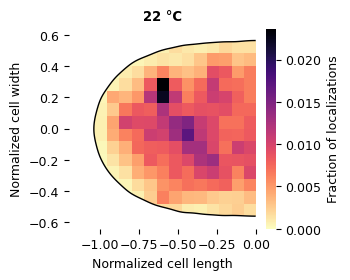

clpx_32HS_5min.csv: 18393 localizations, 187 cells, max bin = 0.0416


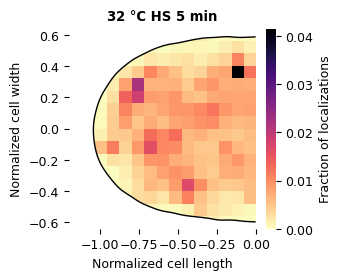

clpx_32HS_15min.csv: 14118 localizations, 139 cells, max bin = 0.0819


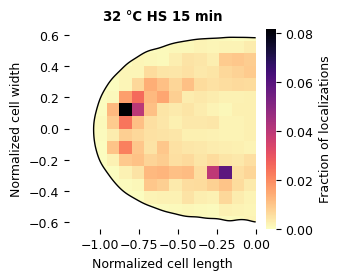

clpx_22REC_5min.csv: 10901 localizations, 157 cells, max bin = 0.0277


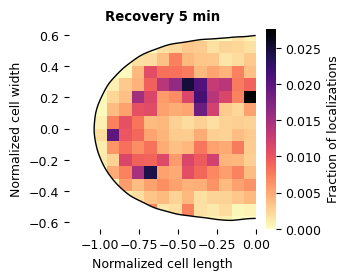

clpx_22REC_15min.csv: 13329 localizations, 127 cells, max bin = 0.0174


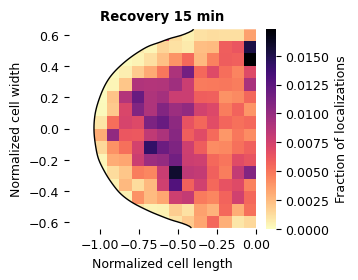

clpx_22REC_30min.csv: 5983 localizations, 100 cells, max bin = 0.0289


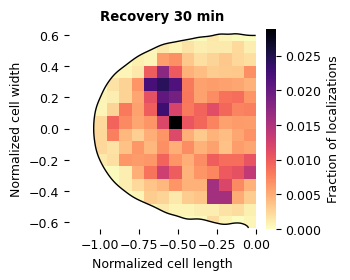

In [20]:
for fname, title in CONDITIONS:
    fig, ax, im = plot_heatmap(os.path.join(CSV_DIR, fname), MASK_DIR, title=title, vmax=VMAX,
                               save=fname.replace(".csv", "_heatmap.svg"))
    plt.show()

## Same colour scale for all conditions
Run the cell above first: it prints `max bin` for every condition. Put the largest value in `VMAX` and re-run, so the colours mean the same thing in every map.

clpx_22deg.csv: 22889 localizations, 251 cells, max bin = 0.0237


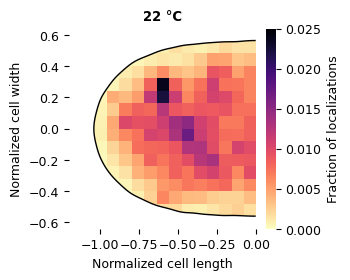

clpx_32HS_5min.csv: 18393 localizations, 187 cells, max bin = 0.0416


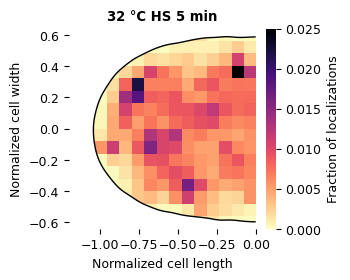

clpx_32HS_15min.csv: 14118 localizations, 139 cells, max bin = 0.0819


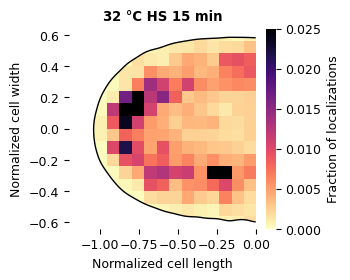

clpx_22REC_5min.csv: 10901 localizations, 157 cells, max bin = 0.0277


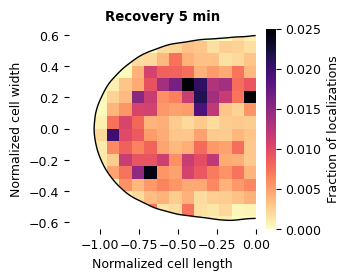

clpx_22REC_15min.csv: 13329 localizations, 127 cells, max bin = 0.0174


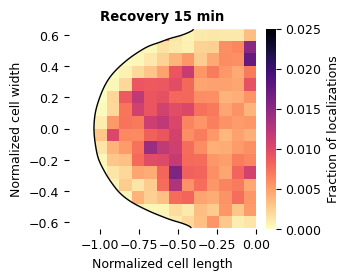

clpx_22REC_30min.csv: 5983 localizations, 100 cells, max bin = 0.0289


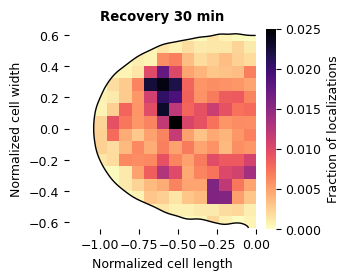

In [22]:
VMAX = 0.025   # <- largest 'max bin' printed above

for fname, title in CONDITIONS:
    fig, ax, im = plot_heatmap(os.path.join(CSV_DIR, fname), MASK_DIR, title=title, vmax=VMAX,
                               save=fname.replace(".csv", "_heatmap_samescale.svg"))
    plt.show()

## Only some molecules (optional)
Same as the original code's Dapp limits, e.g. only slow tracks: `dapp_range=(-3, -1)` (log10 Dapp).

In [ ]:
fig, ax, im = plot_heatmap(os.path.join(CSV_DIR, "clpx_22deg_clean.csv"), MASK_DIR,
                           title="22 °C, D$_{app}$ < 0.1 µm²/s", dapp_range=(-3, -1))
plt.show()